> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Dos países, dos ritmos demográficos
+### México y España · 1950–2023 · Módulo 57 — Storytelling
+
+**Pregunta:** ¿qué revela la comparación de población cuando distinguimos tamaño y cambio relativo?
+
+**Idea principal:** en 1950 ambos países tenían una población similar; sus trayectorias posteriores se separaron. La evidencia procede de estimaciones históricas, sin inferir causas a partir de estas dos series.
+
+**Fuente:** Naciones Unidas, División de Población, *World Population Prospects 2024*, indicador población total al 1 de julio (ambos sexos). Serie publicada en [UNdata](https://data.un.org/Data.aspx?d=PopDiv&f=variableID%3A12%3BcrID%3A484%2C724); archivo masivo [WPP2024_TotalPopulationBySex.csv.gz](https://github.com/unicef-drp/Country-and-Region-Metadata/blob/main/raw_data/WORLD/WPP2024_TotalPopulationBySex.csv.gz) conservado por UNICEF. Archivo de esta entrega: `ONU_WPP2024_Mexico_Espana_1950_2023.csv`. Se utilizan sólo estimaciones 1950–2023, sin proyecciones de 2024 en adelante.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

csv = Path('ONU_WPP2024_Mexico_Espana_1950_2023.csv')
df = pd.read_csv(csv)
assert set(df.pais) == {'Mexico', 'Spain'}
assert df.groupby('pais').anio.agg(['min','max','count']).eq([1950,2023,74]).all().all()
assert not df.duplicated(['pais','anio']).any() and (df.poblacion_miles>0).all()
df['millones'] = df.poblacion_miles / 1000
colores = {'Mexico':'#3A7BD5','Spain':'#6E7A89'}
etiquetas = {'Mexico':'México','Spain':'España'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'figure.facecolor':'white','axes.facecolor':'white'})
print('Filas verificadas:',len(df),'| Intervalo:',df.anio.min(),'-',df.anio.max())
display(df.head(3))

Filas verificadas: 148 | Intervalo: 1950 - 2023


,pais,anio,poblacion_miles,millones
0,Mexico,1950,27587.939,27.587939
1,Mexico,1951,28320.482,28.320482
2,Mexico,1952,29090.173,29.090173


## 1. Partían casi del mismo tamaño
+**Evidencia primero.** Comparamos puntos de partida y cierre; las diferencias están en millones de habitantes. La línea base de las barras es cero para conservar la escala de magnitudes.

anio,1950,2023,cambio_millones,factor
pais,,,,
México,27.59,129.74,102.15,4.70
España,28.08,47.91,19.83,1.71


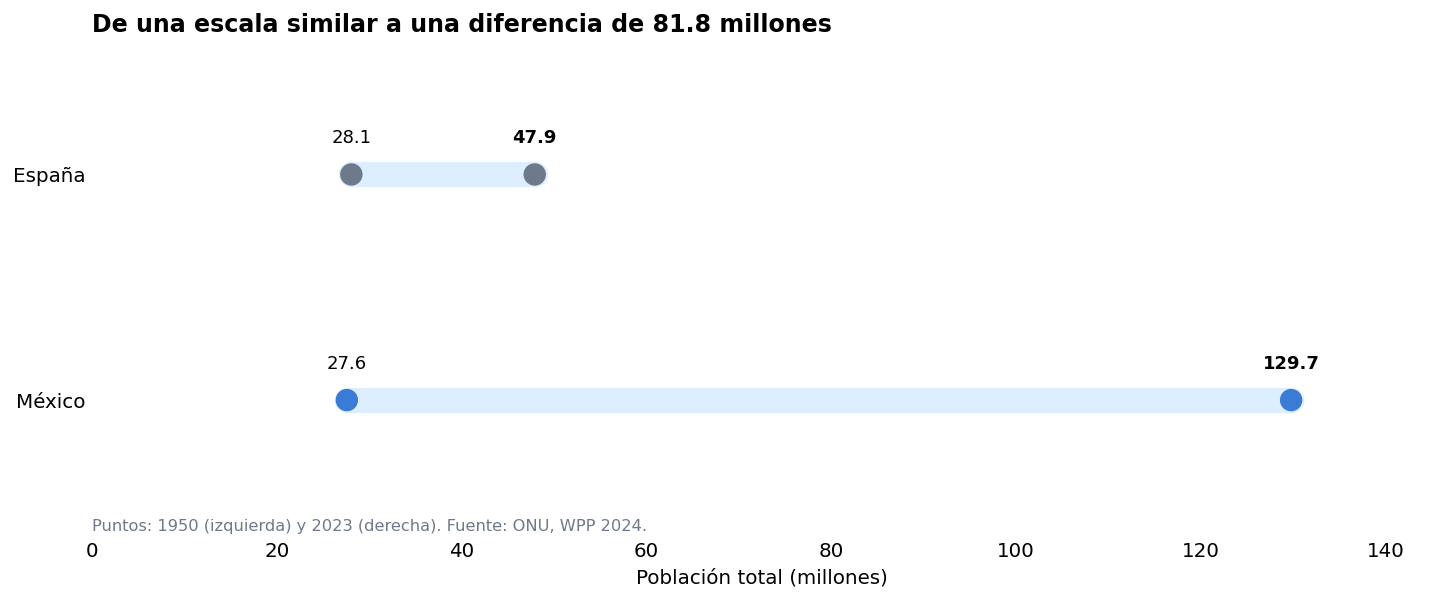

In [2]:
cortes = df[df.anio.isin([1950,2023])].pivot(index='pais',columns='anio',values='millones')
cortes['cambio_millones'] = cortes[2023]-cortes[1950]
cortes['factor'] = cortes[2023]/cortes[1950]
display(cortes.rename(index=etiquetas).round(2))

fig,ax=plt.subplots(figsize=(11,4.5),layout='constrained')
for pais,y in [('Spain',1),('Mexico',0)]:
    x0,x1=cortes.loc[pais,[1950,2023]]
    ax.plot([x0,x1],[y,y],color='#DCEEFF',linewidth=14,solid_capstyle='round',zorder=1)
    ax.scatter([x0,x1],[y,y],s=130,c=[colores[pais]]*2,zorder=2)
    ax.text(x0,y+.14,f'{x0:.1f}',ha='center',fontsize=10)
    ax.text(x1,y+.14,f'{x1:.1f}',ha='center',fontsize=10,fontweight='bold')
ax.set(yticks=[0,1],yticklabels=['México','España'],xlim=(0,145),ylim=(-.60,1.48),xlabel='Población total (millones)')
ax.set_title('De una escala similar a una diferencia de 81.8 millones',loc='left',weight='bold',pad=19)
ax.text(0,-.58,'Puntos: 1950 (izquierda) y 2023 (derecha). Fuente: ONU, WPP 2024.',transform=ax.transData,fontsize=9,color='#6E7A89')
ax.spines[['left','bottom']].set_visible(False)
ax.tick_params(length=0)
plt.show()

**Lectura:** en 1950 España (28.1 millones) y México (27.6) estaban muy cerca. En 2023 México alcanzó 129.7 millones y España 47.9. Esto describe una diferencia de tamaño, pero aún no explica cuándo se abrió la brecha ni cuál creció más respecto a su base.

## 2. ¿Cuándo se abrió la brecha?
+La posición compartida de los años y las líneas continuas facilitan seguir cada trayectoria. Etiquetamos directamente los extremos para evitar saltos visuales hacia una leyenda.

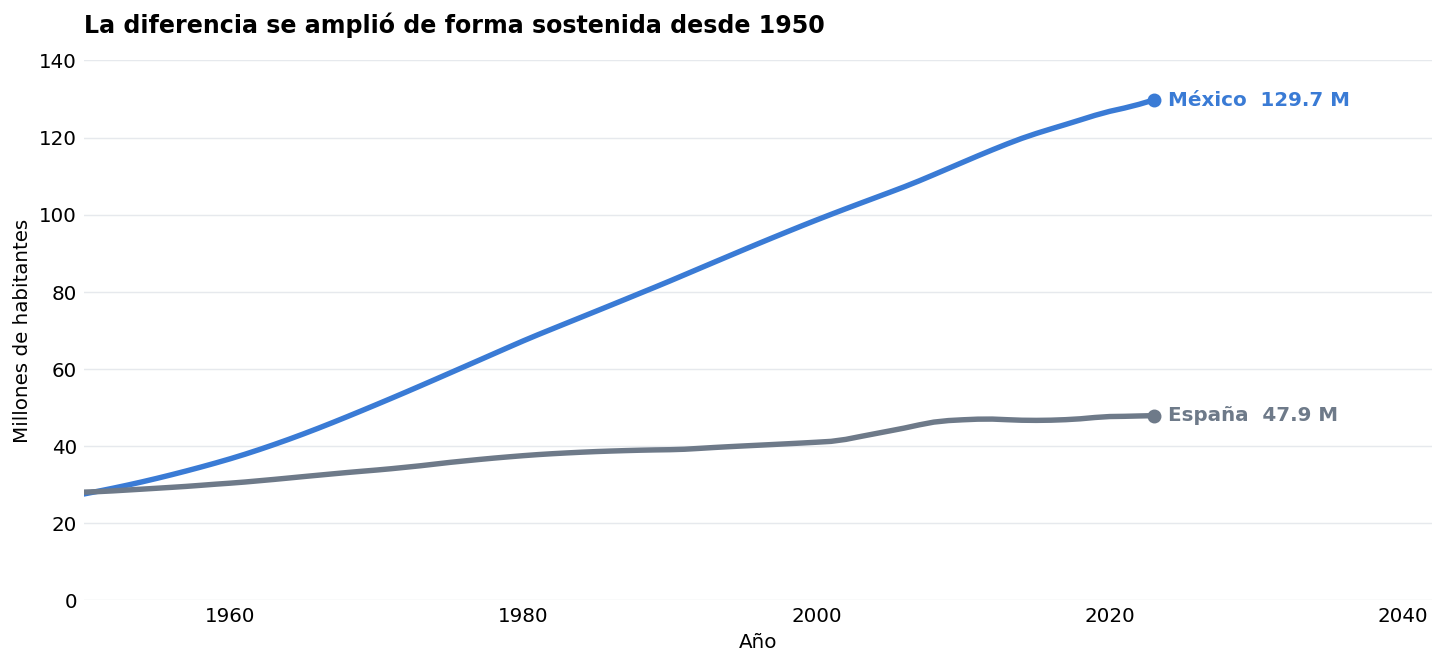

In [3]:
fig,ax=plt.subplots(figsize=(11,5),layout='constrained')
for pais in ['Mexico','Spain']:
    s=df[df.pais.eq(pais)]
    ax.plot(s.anio,s.millones,color=colores[pais],lw=3,label=etiquetas[pais])
    ax.scatter(s.anio.iloc[-1],s.millones.iloc[-1],color=colores[pais],s=45,zorder=3)
    ax.annotate(f'{etiquetas[pais]}  {s.millones.iloc[-1]:.1f} M',
                (2023,s.millones.iloc[-1]),xytext=(8,0),textcoords='offset points',
                color=colores[pais],va='center',weight='bold')
ax.set(xlim=(1950,2042),ylim=(0,140),ylabel='Millones de habitantes',xlabel='Año')
ax.set_title('La diferencia se amplió de forma sostenida desde 1950',loc='left',weight='bold',pad=15)
ax.yaxis.set_major_locator(MultipleLocator(20))
ax.grid(axis='y',color='#E6E9ED')
ax.spines[['left','bottom']].set_visible(False)
ax.tick_params(length=0)
plt.show()

**Lectura:** ambas poblaciones aumentaron en el intervalo completo, con ritmos distintos. La separación crece con el tiempo; la gráfica no identifica las causas (fecundidad, mortalidad o migración requerirían indicadores adicionales).

## 3. El tamaño absoluto puede ocultar la proporción del cambio
+Indexamos cada serie en 1950 = 100. Esto permite comparar el crecimiento acumulado sin confundirlo con el tamaño de partida.

Factores 1950–2023: {'México': 4.7, 'España': 1.71}


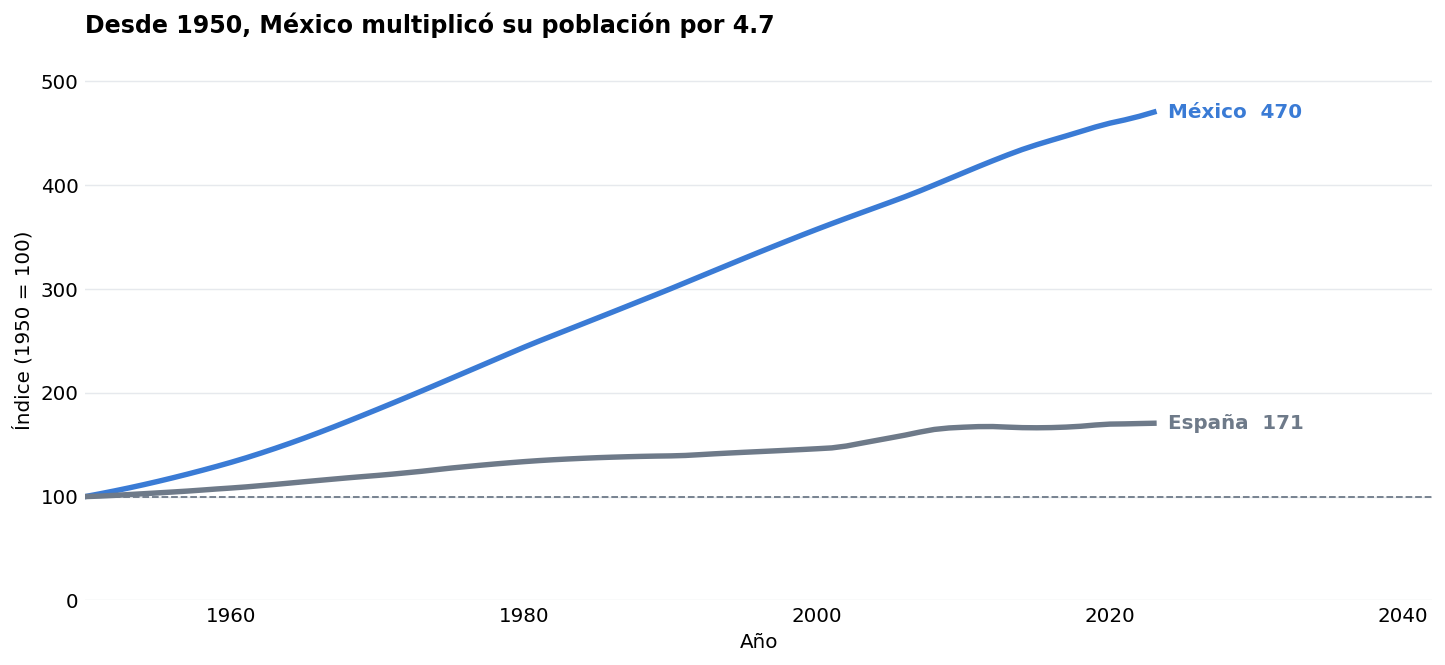

In [4]:
base=df[df.anio.eq(1950)].set_index('pais').millones
df['indice_1950_100']=df.millones/df.pais.map(base)*100
fig,ax=plt.subplots(figsize=(11,5),layout='constrained')
for pais in ['Mexico','Spain']:
    s=df[df.pais.eq(pais)]
    ax.plot(s.anio,s.indice_1950_100,color=colores[pais],lw=3)
    ax.annotate(f'{etiquetas[pais]}  {s.indice_1950_100.iloc[-1]:.0f}',
                (2023,s.indice_1950_100.iloc[-1]),xytext=(8,0),textcoords='offset points',
                color=colores[pais],va='center',weight='bold')
ax.axhline(100,color='#6E7A89',lw=1,ls='--')
ax.set(xlim=(1950,2042),ylim=(0,520),ylabel='Índice (1950 = 100)',xlabel='Año')
ax.set_title('Desde 1950, México multiplicó su población por 4.7',loc='left',weight='bold',pad=15)
ax.grid(axis='y',color='#E6E9ED')
ax.spines[['left','bottom']].set_visible(False)
ax.tick_params(length=0)
plt.show()
print('Factores 1950–2023:',{etiquetas[k]:round(v,2) for k,v in cortes.factor.items()})

## Conclusión y límites
+1. **Demostrado por los datos:** México pasó de 27.6 a 129.7 millones (×4.70); España, de 28.1 a 47.9 millones (×1.71). En 2023 la distancia era de 81.8 millones.
+2. **Interpretación sustentada:** las dos series crecieron, pero México lo hizo mucho más en términos absolutos y relativos durante 1950–2023.
+3. **Por investigar:** cambios en fecundidad, mortalidad y migración pueden contribuir a explicar la divergencia; esta entrega no permite atribuir pesos causales.
+4. **Validación futura:** añadir esos indicadores de la ONU, armonizar sus periodos y comprobar si explican las etapas de mayor separación.
+
+### Decisiones visuales aplicadas
+
+| Principio | Decisión visible | Para qué sirve |
+|:--|:--|:--|
+| Gestalt: similitud | Azul constante para México; gris constante para España | Reconocer el país en las tres figuras |
+| Gestalt: continuidad | Líneas conectadas y eje temporal común | Seguir cada trayectoria sin reordenamientos |
+| Gestalt: proximidad | Valores y nombres junto a extremos de líneas y puntos | Asociar anotaciones con sus datos |
+| Prägnanz o buena forma | Dos series, títulos con mensajes y escalas sencillas | Identificar el patrón principal sin esfuerzo innecesario |
+| Tufte: claridad y economía gráfica | Sin 3D, sombras ni bordes superfluos; rejilla tenue | Priorizar los datos sobre adornos |
+| Holmes: recursos narrativos al servicio del dato | Títulos que anticipan el hallazgo y secuencia inicio → evolución → índice | Contar una historia legible sin ilustraciones que distorsionen magnitudes |
+
+**Precisión:** población al 1 de julio en miles en el CSV original; los gráficos expresan millones. La edición 2024 ofrece estimaciones históricas hasta 2023 y proyecciones desde 2024. Los valores son estimaciones demográficas, no recuentos censales anuales. No se extrapolan resultados fuera del periodo.